# Milky Way Wolf-Rayet populations

In [1]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np

from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde

# custom helper scripts
from helper_functions import calc_Teff, optical_depth_calculation

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

In [2]:
tol_vibrant

array([[0.        , 0.46666667, 0.73333333, 1.        ],
       [0.2       , 0.73333333, 0.93333333, 1.        ],
       [0.        , 0.6       , 0.53333333, 1.        ],
       [0.93333333, 0.46666667, 0.2       , 1.        ],
       [0.8       , 0.2       , 0.06666667, 1.        ],
       [0.93333333, 0.2       , 0.46666667, 1.        ],
       [0.73333333, 0.73333333, 0.73333333, 1.        ]])

In [3]:
data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
metallicity = 1.0
met_str = convert_metallicity_to_string(metallicity)
file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
with open(file_path, 'rb') as f:
    data = pickle.load(f)
    
S1_WR_data = data['S1_WR_data']
S2_WR_data = data['S2_WR_data']


In [4]:
# hydrogen-poor/free stars

WR_types = []
time_array = []
weight_array = []
state_array = []
key_array = []
star_array = []  # Track whether entry is from S1 or S2
period_array = []
separation_array = []
Teff_array = []
L_array = []
optical_depth_array = []
surface_H_array = []
surface_He_array = []
mass_array = []
mass_companion_array = []
radius_array = []
Mdot_array = []
companion_array = []
S1_state_array = []
surface_C = []
optical_depth = []

for key in tqdm(S1_WR_data):
    data = S1_WR_data[key]['data']
    weights = S1_WR_data[key]['weights']
    optical_depth_array.extend(S1_WR_data[key]['optical_depth'])
    
    surface_H_array.extend(data['S1_surface_h1'].values)
    surface_He_array.extend(data['S1_surface_he4'].values)
    Teff = 10**calc_Teff(data['S1_log_L'], data['S1_log_R'])
         
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    S1_state_array.extend(data['S1_state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S1'] * len(data))  # Mark as S1
    Teff_array.extend(Teff)
    L_array.extend(10**data['S1_log_L'].values)
    mass_array.extend(data['S1_mass'].values)
    mass_companion_array.extend(data['S2_mass'].values)
    radius_array.extend(10**data['S1_log_R'].values)
    Mdot_array.extend(10**data['S1_lg_mdot'].values)
    companion_array.extend(data['S2_state'].values)
    
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S1_mass'].values,
                                         data['S2_mass'].values)
    
    separation_array.extend(sep)
    
    
for key in tqdm(S2_WR_data):
    data = S2_WR_data[key]['data']
    weights = S2_WR_data[key]['weights']
    optical_depth_array.extend(S2_WR_data[key]['optical_depth'])
    
    surface_H_array.extend(data['S2_surface_h1'].values)
    surface_He_array.extend(data['S2_surface_he4'].values)
    Teff = 10**calc_Teff(data['S2_log_L'], data['S2_log_R'])
    
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    star_array.extend(['S2'] * len(data))  # Mark as S2
    Teff_array.extend(Teff)
    L_array.extend(10**data['S2_log_L'].values)
    mass_array.extend(data['S2_mass'].values)
    mass_companion_array.extend(data['S1_mass'].values)
    radius_array.extend(10**data['S2_log_R'].values)
    Mdot_array.extend(10**data['S2_lg_mdot'].values)
    companion_array.extend(data['S1_state'])
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S2_mass'].values,
                                         data['S1_mass'].values)
    S1_state_array.extend(data['S2_state'].values)
    separation_array.extend(sep)
    

WR_types = np.array(WR_types)
time_array = np.array(time_array)
weight_array = np.array(weight_array)
state_array = np.array(state_array)
key_array = np.array(key_array)
star_array = np.array(star_array)  # Convert to array
period_array = np.array(period_array)
separation_array = np.array(separation_array)
Teff_array = np.array(Teff_array)
L_array = np.array(L_array)
optical_depth_array = np.array(optical_depth_array)
surface_H_array = np.array(surface_H_array)
surface_He_array = np.array(surface_He_array)
mass_array = np.array(mass_array)
radius_array = np.array(radius_array)
Mdot_array = np.array(Mdot_array)
companion_array = np.array(companion_array)
mass_companion_array = np.array(mass_companion_array)

100%|██████████| 38190/38190 [00:18<00:00, 2059.41it/s]


# Period distribution of different WR binaries

In [5]:
WNL =  (surface_H_array > 0.05) & (surface_H_array <= 0.4) & (optical_depth_array > 1.5) & ~(np.char.find(S1_state_array, 'H_burning') != -1)
WNE = (surface_H_array <= 0.05) & (surface_He_array >= 0.7) & (optical_depth_array > 1.5)
WC = (surface_H_array <= 0.05) & (surface_He_array < 0.7) & (optical_depth_array > 1.5)

In [6]:
# mask_H_burning = np.char.find(S1_state_array, 'H_burning') != -1 

# WNL = (surface_H_array > 0.05) & (surface_H_array < 0.4) & ~mask_H_burning & (optical_depth_array > 0.5)
# WNE = (surface_H_array <= 0.05) & (surface_He_array >= 0.7) & (optical_depth_array > 1.5)
# WC = (surface_H_array <= 0.05) & (surface_He_array < 0.7) & (optical_depth_array > 1.5)

In [7]:
binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')

In [8]:
print(np.sum(weight_array[binary_mask & WNL])/np.sum(weight_array[binary_mask & (WNL | WNE | WC)]))
print(np.sum(weight_array[binary_mask & WNE])/np.sum(weight_array[binary_mask & (WNL | WNE | WC)]))
print(np.sum(weight_array[binary_mask & WC])/np.sum(weight_array[binary_mask & (WNL | WNE | WC)]))

0.1289777838085814
0.5862453547340378
0.2847768614573807


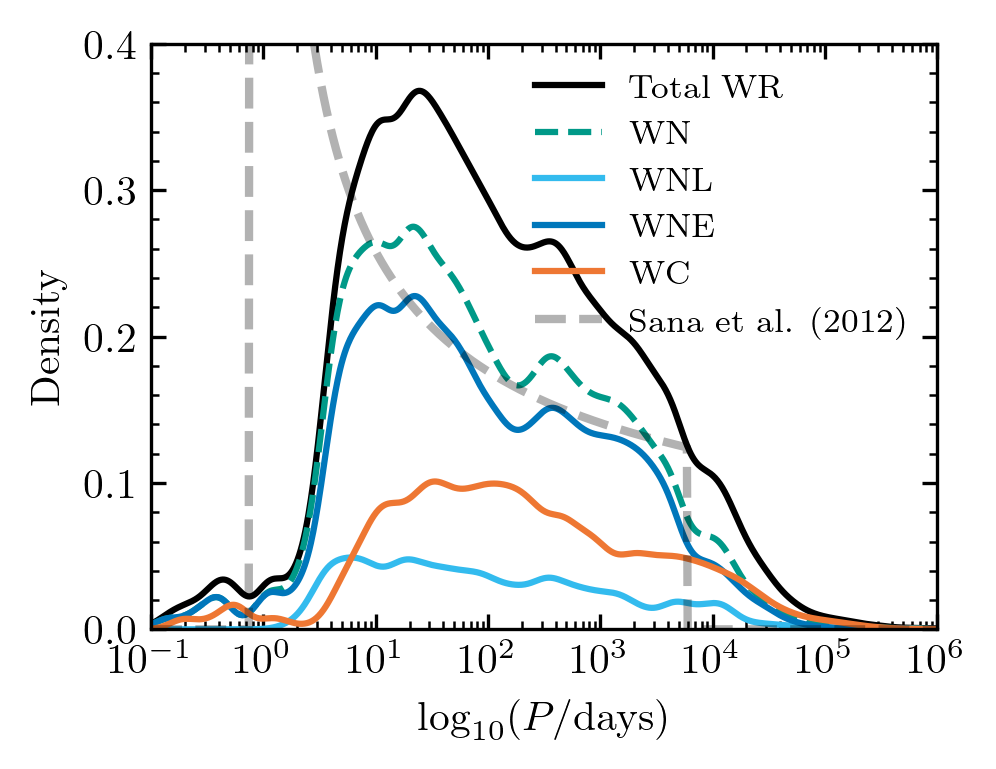

In [9]:
from posydon.popsyn.distributions import Sana12Period
period_selection = period_array[(binary_mask) & (WNL| WNE | WC)]

bw = 0.1

# all WRs in binaries
total_weight = np.sum(weight_array[(binary_mask) & (WNL| WNE | WC)])

kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNL| WNE | WC)], bw_method=bw)
x_eval = np.linspace(-1,6, 1000)
kde_eval = kde(x_eval)
plt.plot(10**x_eval, kde_eval, color='black', label='Total WR')

# all WN in binaries
period_selection = period_array[(binary_mask) & (WNL| WNE)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNL| WNE)], bw_method=bw)
kde_eval = kde(x_eval)
fraction = np.sum(weight_array[(binary_mask) & (WNL| WNE)]) / np.sum(weight_array[(binary_mask) & (WNL| WNE | WC)])
plt.plot(10**x_eval, kde_eval*fraction, color=tol_vibrant[2], label='WN', ls='--')

# WNL
period_selection = period_array[(binary_mask) & (WNL)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNL)], bw_method=bw)
kde_eval = kde(x_eval)
fraction = np.sum(weight_array[(binary_mask) & (WNL)]) / np.sum(weight_array[(binary_mask) & (WNL| WNE | WC)])
plt.plot(10**x_eval, kde_eval*fraction, color=tol_vibrant[1], label='WNL')

# WNE 
period_selection = period_array[(binary_mask) & (WNE)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WNE)], bw_method=bw)
kde_eval = kde(x_eval)
fraction = np.sum(weight_array[(binary_mask) & (WNE)]) / np.sum(weight_array[(binary_mask) & (WNL | WNE | WC)])
plt.plot(10**x_eval, kde_eval*fraction, color=tol_vibrant[0], label='WNE')


# all WC in binaries
period_selection = period_array[(binary_mask) & (WC)]
kde = gaussian_kde(np.log10(period_selection), weights=weight_array[(binary_mask) & (WC)], bw_method=bw)
kde_eval = kde(x_eval)
fraction = np.sum(weight_array[(binary_mask) & (WC)]) / np.sum(weight_array[(binary_mask) & (WNL| WNE | WC)])
plt.plot(10**x_eval, kde_eval*fraction, color=tol_vibrant[3], label='WC')

sana_dist = Sana12Period(p_min=0.75, p_max=6000.0)

# For massive stars (>15 Msun), evaluate the distribution
# Use a representative mass of ~20 Msun for typical WR progenitor
m_wr_progenitor = 20.0

# normalised to 1 in logspace, so this should be fine.
period_eval = 10**x_eval
sana_pdf = sana_dist.pdf(period_eval, m_wr_progenitor)
plt.plot(10**x_eval, sana_pdf, 'k--', linewidth=2, alpha=0.3, 
         label=f'Sana et al. (2012)')


plt.xscale('log')
plt.xlabel('$\log_{10}(P/\mathrm{days})$')
plt.ylabel('Density')
plt.legend()
plt.xlim(1e-1, 1e6)
plt.ylim(0, 0.4)
figure_paths = '/Users/max/Documents/projects/WR_population/analysis/figures/'

plt.savefig(figure_paths + 'pdf/MW_WR_period_distributions.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_WR_period_distributions.png', bbox_inches='tight', dpi=300)
plt.show()

In [16]:
met_str

'1e+00'

In [18]:
from posydon.popsyn.synthetic_population import Population
import pandas as pd
population_run_folder = Path('/Users/max/Documents/projects/WR_population/population_synthesis/runs/2025_11_04/')
population_file = population_run_folder / f"{met_str}_Zsun_population.h5"

pop = Population(str(population_file))

HMS_HMS_interaction = pop.oneline['interp_class_HMS_HMS']
CO_HMS_RLO_interaction = pop.oneline['interp_class_CO_HMS_RLO']

S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'reverse_stable_MT')[0])
S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

# S1 interaction masks - only apply to S1 entries
S1_entries = (star_array == 'S1')
S1_mask_stable = S1_entries & np.isin(key_array, np.array(list(S1_stable_indices)))
S1_mask_unstable = S1_entries & np.isin(key_array, np.array(list(S1_unstable_indices)))
S1_mask_reverse_stable = S1_entries & np.isin(key_array, np.array(list(S1_reverse_stable_indices)))
S1_mask_no_MT = S1_entries & np.isin(key_array, np.array(list(S1_no_MT_indices)))


S2_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'stable_MT')[0])
S2_unstable_indices = set(np.where(CO_HMS_RLO_interaction == 'unstable_MT')[0])
S2_reverse_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'reverse_stable_MT')[0])
S2_no_MT_indices = set(np.where((CO_HMS_RLO_interaction == 'no_MT') | pd.isna(CO_HMS_RLO_interaction))[0])

# S2 interaction masks - only apply to S2 entries
S2_entries = (star_array == 'S2')
S2_mask_stable = S2_entries & np.isin(key_array, np.array(list(S2_stable_indices)))
S2_mask_unstable = S2_entries & np.isin(key_array, np.array(list(S2_unstable_indices)))
S2_mask_reverse_stable = S2_entries & np.isin(key_array, np.array(list(S2_reverse_stable_indices)))
S2_mask_no_MT = S2_entries & np.isin(key_array, np.array(list(S2_no_MT_indices)))

Missing ini parameter: metallicity


WNL: 0.1289777838085814
WNE: 0.5862453547340378
Stable (S1): 0.454
Stable (S2): 0.165
Unstable (S1): 0.017
Unstable (S2): 0.030
No MT (S1): 0.245
No MT (S2): 0.063
WC: 0.2847768614573807
Stable (S1): 0.327
Stable (S2): 0.091
Unstable (S1): 0.009
Unstable (S2): 0.034
No MT (S1): 0.362
No MT (S2): 0.159


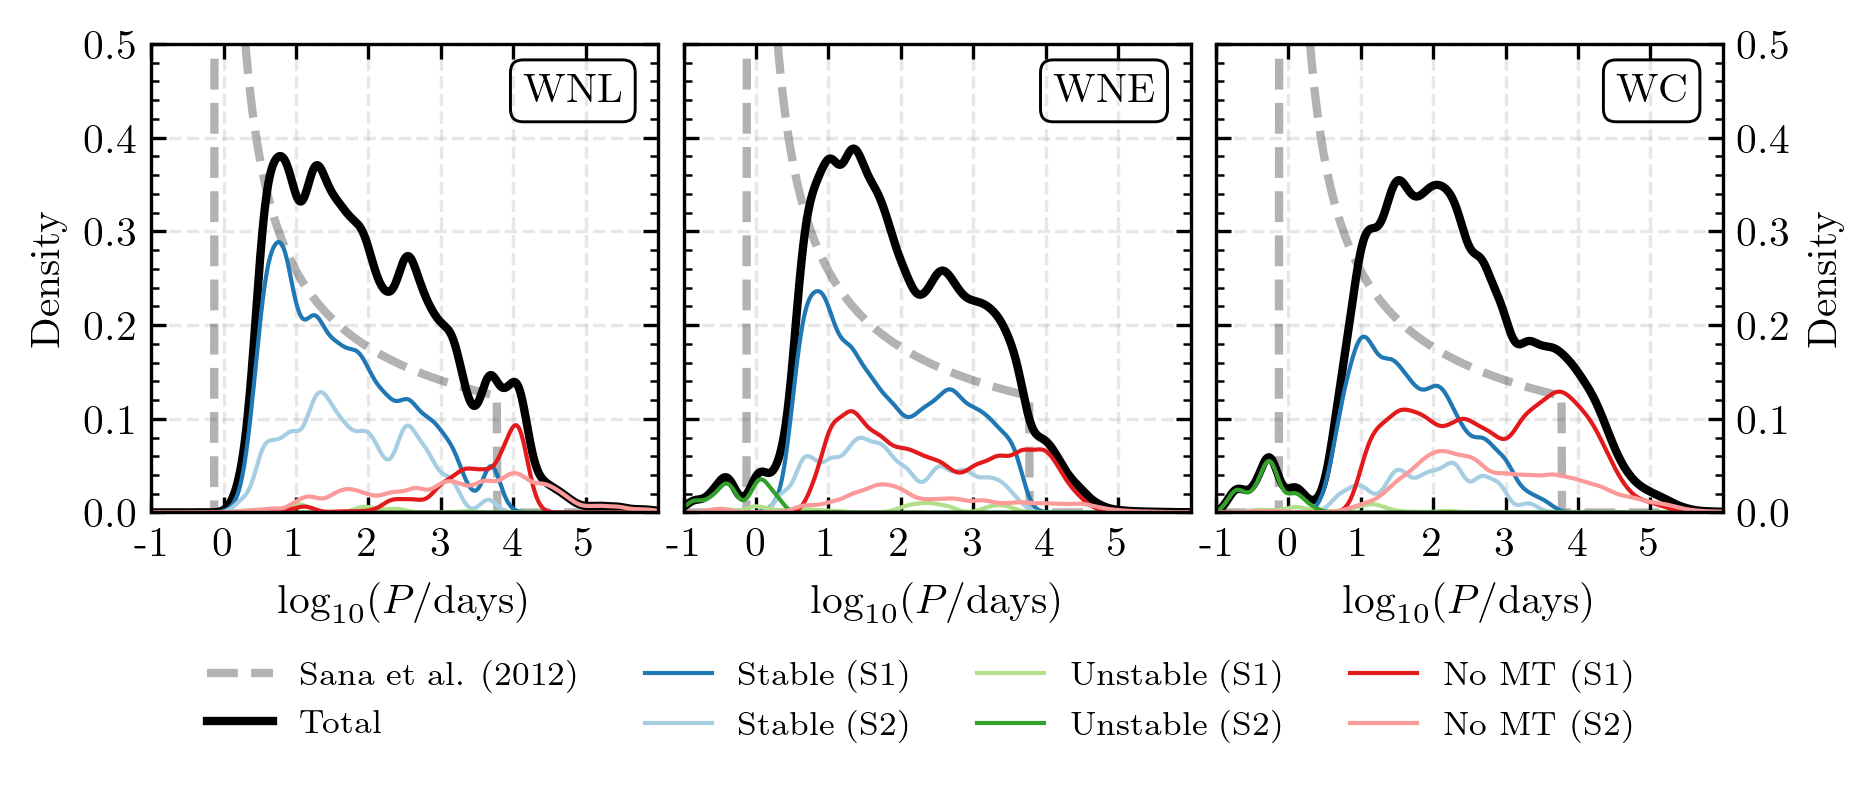

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(3.38*2, 2.535*0.8))

x_eval = np.linspace(-1, 6, 1000)
sana_dist = Sana12Period(p_min=0.75, p_max=6000.0)


mask = binary_mask

MT_interactions = {'Stable (S1)': S1_mask_stable,
                   'Stable (S2)': S2_mask_stable,
                   'Unstable (S1)': S1_mask_unstable,
                   'Unstable (S2)': S2_mask_unstable,
                   'No MT (S1)': S1_mask_no_MT,
                   'No MT (S2)': S2_mask_no_MT,
                   'Reverse Stable (S1)': S1_mask_reverse_stable,}


colours = Colormap('colorbrewer:Paired_8')(np.linspace(0,1,8))

colours = {"Stable (S1)": colours[1],
           "Stable (S2)": colours[0],

           "Unstable (S1)": colours[2],
           "Unstable (S2)": colours[3],

           "No MT (S1)": colours[5],
           "No MT (S2)": colours[4],
           
           "Reverse Stable (S1)": colours[7],
           }


# Setup Sana+12 distribution
m_wr_progenitor = 20.0
period_eval = 10**x_eval
sana_pdf = sana_dist.pdf(period_eval, m_wr_progenitor)
for ax in axes:
    ax.plot(10**x_eval, sana_pdf, 'k--', linewidth=2, alpha=0.3, 
         label=f'Sana et al. (2012)')



# plot WNL
kde = gaussian_kde(np.log10(period_array[mask & WNL]), weights=weight_array[mask & WNL], bw_method=0.1)
kde_eval = kde(x_eval)
axes[0].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

# get covariance
cho_cov = kde.cho_cov

# different MT interactions
print("WNL:", weight_array[mask & WNL].sum()/weight_array[mask & (WNL | WNE | WC)].sum())
total = 0
not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
for label, mt_mask in MT_interactions.items():
    if np.sum(weight_array[mask & WNL & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WNL & mt_mask]), weights=weight_array[mask & WNL & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[mask & WNL & mt_mask]) / np.sum(weight_array[mask & WNL])
    total += fraction
    print(f"{label}: {fraction:.3f}")
    axes[0].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=1, color=colours[label])

# Plot WNE
kde = gaussian_kde(np.log10(period_array[mask & WNE]), weights=weight_array[mask & WNE], bw_method=0.1)
cho_cov = kde.cho_cov # get covariance to use for all WNE KDEs
kde_eval = kde(x_eval)
axes[1].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

print("WNE:", weight_array[mask & WNE].sum()/weight_array[mask & (WNL | WNE | WC)].sum())
for label, mt_mask in MT_interactions.items():
    if np.sum(weight_array[mask & WNE & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WNE & mt_mask]), weights=weight_array[mask & WNE & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[mask & WNE & mt_mask]) / np.sum(weight_array[mask & WNE])
    print(f"{label}: {fraction:.3f}")
    axes[1].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=1, color=colours[label])


# plot WC
kde = gaussian_kde(np.log10(period_array[mask & WC]), weights=weight_array[mask & WC], bw_method=0.1)
cho_cov = kde.cho_cov # get covariance to use for all WC KDEs
kde_eval = kde(x_eval)
axes[2].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)

print("WC:", weight_array[mask & WC].sum()/weight_array[mask & (WNL | WNE | WC)].sum())
for label, mt_mask in MT_interactions.items():
    if np.sum(weight_array[mask & WC & mt_mask]) == 0:
        continue  # Skip if no data points for this interaction type
    kde = gaussian_kde(np.log10(period_array[mask & WC & mt_mask]), weights=weight_array[mask & WC & mt_mask], bw_method=0.1)
    kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
    kde_eval = kde(x_eval)
    fraction = np.sum(weight_array[mask & WC & mt_mask]) / np.sum(weight_array[mask & WC])
    print(f"{label}: {fraction:.3f}")
    axes[2].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=1, color=colours[label])


# Housekeeping for layout

for ax in axes:
    ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
    ax.set_xscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
    ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
    ax.set_ylim(0, 0.5)
    ax.grid(True, which='major', ls='--', alpha=0.3)
    

axes[0].set_ylabel('Density')
axes[1].legend(loc='upper left', bbox_to_anchor=(-1, -0.25), ncol=4)

axes[1].set_yticklabels([])
# move ytick label to right side for right plot
axes[-1].set_ylabel('Density')
axes[-1].yaxis.set_label_position("right")
axes[-1].yaxis.set_tick_params(left=True, right=True, labelleft=False, labelright=True)

axes[0].text(0.93, 0.9, 'WNL', transform=axes[0].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
axes[1].text(0.93, 0.9, 'WNE', transform=axes[1].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))
axes[2].text(0.93, 0.9, 'WC', transform=axes[2].transAxes, ha='right', va='center',
             bbox=dict(facecolor='none', edgecolor='black', boxstyle='round, pad=0.3', lw=0.7))

plt.subplots_adjust(wspace=0.05)

figure_paths = '/Users/max/Documents/projects/WR_population/analysis/figures/'
plt.savefig(figure_paths + 'pdf/MW_WR_period_distributions_MT.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_WR_period_distributions_MT.png', bbox_inches='tight', dpi=300)
plt.show()

In [32]:
pop.history[235]

,state,event,time,orbital_period,eccentricity,lg_mtransfer_rate,step_names,step_times,S1_state,S1_mass,...,S2_he_core_mass,S2_he_core_radius,S2_co_core_mass,S2_co_core_radius,S2_center_h1,S2_center_he4,S2_surface_h1,S2_surface_he4,S2_surf_avg_omega_div_omega_crit,S2_spin
binary_index,,,,,,,,,,,,,,,,,,,,,
235,detached,ZAMS,0.000000e+00,1.782253e+02,0.0,NaN,initial_cond,0.000000,H-rich_Core_H_burning,23.418718,...,0.000000,NaN,NaN,NaN,0.715500,2.703000e-01,NaN,NaN,NaN,NaN
235,detached,NaN,4.246062e+01,1.930698e+02,0.0,-99.0,step_HMS_HMS,0.057261,H-rich_Core_H_burning,22.325717,...,0.000000,0.0,0.000000,0.000000,0.714461,2.709868e-01,7.155000e-01,0.270271,0.002085,0.050900
235,detached,NaN,4.246062e+01,1.930698e+02,0.0,-99.0,NaN,NaN,H-rich_Core_H_burning,22.325717,...,0.000000,0.0,0.000000,0.000000,0.714461,2.709868e-01,7.155000e-01,0.270271,0.002085,0.050900
235,detached,NaN,5.684013e+06,2.025265e+02,0.0,-99.0,NaN,NaN,H-rich_Core_H_burning,21.786235,...,0.000000,0.0,0.000000,0.000000,0.370682,6.154623e-01,7.155000e-01,0.270271,0.002141,0.042684
235,detached,NaN,7.827171e+06,2.091066e+02,0.0,-99.0,NaN,NaN,H-rich_Core_H_burning,21.434964,...,0.000000,0.0,0.000000,0.000000,0.131150,8.549973e-01,7.155000e-01,0.270271,0.002061,0.035801
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,disrupted,NaN,9.229943e+06,1.048084e+99,0.0,NaN,NaN,NaN,BH,4.098708,...,7.443520,NaN,6.550009,0.143245,0.000000,6.831590e-14,3.724005e-68,0.417870,0.000087,0.000622
235,disrupted,NaN,9.230958e+06,1.048580e+99,0.0,NaN,NaN,NaN,BH,4.098708,...,7.432618,NaN,6.552550,0.135677,0.000000,2.574230e-13,9.987923e-100,0.413151,0.000096,0.000610
235,disrupted,CC2,9.231973e+06,NaN,NaN,NaN,NaN,NaN,BH,4.098708,...,7.421052,NaN,6.550601,0.109977,0.000000,2.876354e-12,1.000000e-99,0.408142,0.000149,0.000593


In [12]:



print(10)





10
